# FV Convergence, REA and the method of lines

We will re-use the FV solver of notebook 14, with the same four slopes.

* **Part I.** Convergence analysis

* **Part II.** Time step -> REA

* **Part III.** Method of lines.

We solve the same equation as before,

$$\frac{\partial u}{\partial t} + \frac{\partial F(u)}{\partial x} = 0,
\qquad F(u) = c\,u$$

**Reference**: M. Zingale, *Introduction to Computational Astrophysical Hydrodynamics*, Section 5.2.2, Exercise 5.4 and Section 5.3.

Notation follows the lectures: $u$ is the advected state, $c$ the advection speed and $C = c\,\Delta t/\Delta x$ the Courant number.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Grid -> function

We add the grid inside the function, so that we can call it with different values of `nx`.

In [2]:
# minmod function

def minmod(a, b):

    if abs(a) <= abs(b) and a*b > 0.0:
        return a

    if abs(b) <= abs(a) and a*b > 0.0:
        return b

    else:
        return 0.0

In [3]:
def advect(nx, method, cfl = 0.8, num_periods = 5.):

    # Domain limits
    xmin = 0.
    xmax = 1.

    # Number of ghost cells on each side
    ng = 2

    # Lowest and highest indices
    ilo = ng
    ihi = ng + nx - 1

    # Step size and cell centres
    dx = (xmax - xmin)/(nx)
    x = xmin + (np.arange(nx + 2*ng) - ng + 0.5)*dx

    # Empty vector for the solution in double precision:
    u = np.zeros((nx + 2*ng), dtype = np.float64)

    # Add initial conditions
    u[:] = 1. + np.exp(-60.*(x - 0.5)**2)
    #u[np.logical_and(x >= 1./3., x <= 2./3.)] = 1.

    # Make a copy of the initial condition:
    u0 = u.copy()

    # Define perturbation velocity
    c = 1.

    # Maximum simulation time: num_periods periods
    tmax = num_periods*(xmax - xmin)/c

    # Initialise
    t = 0.

    # We start while:
    while t < tmax:

        # Fill up the boundary conditions BCs
        for n in range(ng):
            u[ilo - 1 - n] = u[ihi - n]
            u[ihi + 1 + n] = u[ilo + n]

        # Get time step
        dt = cfl*dx/c

        if t + dt > tmax:
            dt = tmax - t

        # Empty vector for the slope
        slope = np.zeros((nx + 2*ng), dtype = np.float64)

        if method == "godunov":
            # 1st approach: Godunov approach
            slope[:] = 0.
        elif method == "unlimited":
            # 2nd approach: Centred difference method
            for i in range(ilo - 1, ihi + 2):
                slope[i] = 0.5*(u[i + 1] - u[i - 1])/dx
        elif method == "minmod":
            # 3rd approach: minmod limiter
            for i in range(ilo - 1, ihi + 2):
                slope[i] = minmod((u[i] - u[i-1])/dx, (u[i+1] - u[i])/dx)
        elif method == "mc":
            # 4th approach: MC limiter
            for i in range(ilo - 1, ihi + 2):
                slope[i] = minmod(minmod(2*(u[i] - u[i-1])/dx, 2*(u[i+1] - u[i])/dx), 0.5*(u[i+1] - u[i-1])/dx)

        # Empty vectors for the L and R states
        ul = np.zeros((nx + 2*ng), dtype = np.float64)
        ur = np.zeros((nx + 2*ng), dtype = np.float64)

        for i in range(ilo, ihi + 2):

            # Compute L state
            ul[i] = u[i - 1] + 0.5*dx*(1. - c*dt/dx)*slope[i-1]

            # Compute R state
            ur[i] = u[i] - 0.5*dx*(1. + c*dt/dx)*slope[i]

        # Solve Riemann problem
        if c > 0.:
            flux = c*ul
        else:
            flux = c*ur

        # Do the conservative update
        unew = np.zeros((nx + 2*ng), dtype = np.float64)
        unew[ilo:ihi+1] = u[ilo:ihi+1] - dt/dx*(flux[ilo+1:ihi+2]\
                          - flux[ilo:ihi+1])

        # Retrieve solution
        u[:] = unew[:]

        # Advance in time
        t += dt

    return x[ilo:ihi+1], u[ilo:ihi+1], u0[ilo:ihi+1]

## Part I. Convergence

- Run the first-order solver for several different values of $\Delta x$, each a factor of 2 smaller than the previous. Compute $\varepsilon$ for each resolution and observe that it converges in a first-order fashion (i.e. $\varepsilon$ decreases by 2 when we decrease $\Delta x$ by a factor of 2).

- Do the same with the second-order solver and observe that it converges as second-order. However: you may find less than second-order if your initial conditions have discontinuities and you are limiting.

- After one period on a periodic grid the exact solution is the initial condition again, so everything that is left is numerical error. We measure it with the $L_2$ norm:

$$\varepsilon = \| u^{\rm final} - u^{\rm init} \|_2 = \left[ \frac{1}{N}\sum_{i=1}^{N} \left( u_i^{\rm final} - u_i^{\rm init}\right)^2 \right]^{1/2}$$

- The factor of $1/N$ is important; without it the sum grows with the number of cells and the numbers at different resolutions could not be compared.

In [4]:
def error(u, u0):
    # L2 norm 
    N = len(u)
    return np.sqrt(np.sum((u - u0)**2)/N)

In [5]:
# Resolutions
nxs = [32, 64, 128, 256, 512]

# Slopes
methods = ["godunov", "unlimited", "mc", "minmod"]

# Dictionary to store the errors
errors = {}

for method in methods:
    errors[method] = []
    for nx in nxs:
        x, u, u0 = advect(nx, method, cfl = 0.8, num_periods = 5.)
        errors[method].append(error(u, u0))

In [6]:
# Pass to arrays
nxs = np.array(nxs)

### Convergence plot:

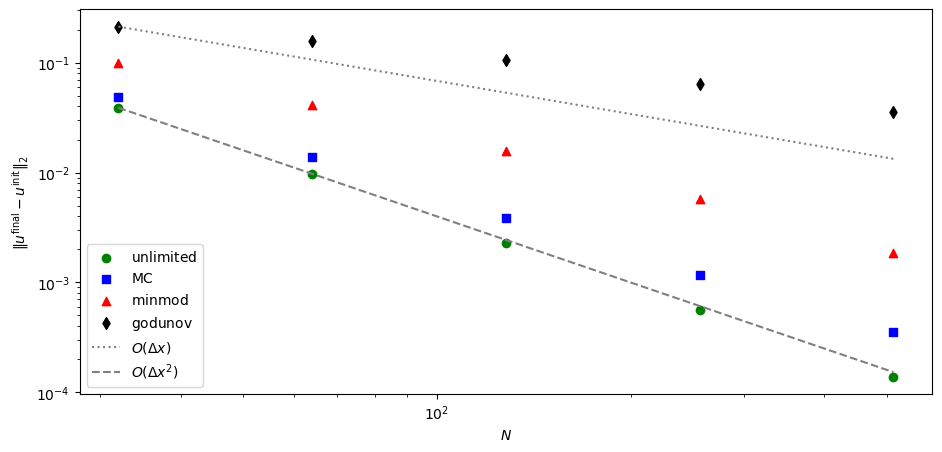

In [7]:
# Plotting the convergence

plt.figure(figsize=(11,5))

plt.scatter(nxs, errors["unlimited"], marker = "o", color = "green", label = r"${\rm unlimited}$")
plt.scatter(nxs, errors["mc"], marker = "s", color = "blue", label = r"${\rm MC}$")
plt.scatter(nxs, errors["minmod"], marker = "^", color = "red", label = r"${\rm minmod}$")
plt.scatter(nxs, errors["godunov"], marker = "d", color = "black", label = r"${\rm godunov}$")

# First order
plt.plot(nxs, errors["godunov"][0]*(nxs[0]/nxs)**1, color = "grey", linestyle = ":", label = r"$O(\Delta x)$")

# Second order
plt.plot(nxs, errors["unlimited"][0]*(nxs[0]/nxs)**2, color = "grey", linestyle = "--", label = r"$O(\Delta x^2)$")

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$N$")
plt.ylabel(r"$\| u^{\rm final} - u^{\rm init}\|_2$")
plt.legend()
plt.show()

### Observations:

- **unlimited** sits on the $O(\Delta x^2)$ line: the error falls by a factor of 4 for every refinement.

- **MC** is close to second order, **minmod** is clearly worse. Both limiters clip the slope near the peak of the Gaussian, and that costs accuracy even though the profile is perfectly smooth.

- **godunov** is heading for the $O(\Delta x)$ line, but the measured order on the coarse grids is well below 1. The Gaussian is simply not resolved on 32 cells, the order climb towards 1 as the grid is refined.


## Part II. Reconstruct, evolve, average (REA) method

Now we look at a single step using REA:

- Reconstruct a line in every cell

- Shift (evolve) the profile by $c\,\Delta t = C\,\Delta x$, and

- Re-average in the new cell.

The fraction $C$ of the cell on the left of the interface comes in, and the fraction $1-C$ of this cell stays:

$$\mathcal{I}_{<} = u_{i-1} + \tfrac{1}{2}\Delta u_{i-1}\left( 1 - C\right)$$

$$\mathcal{I}_{>} = u_{i} - \tfrac{1}{2}\Delta u_{i}\,C$$

$$u_i^{\,n+1} = C\,\mathcal{I}_{<} + \left( 1 - C\right)\mathcal{I}_{>}$$

In [8]:
def advect_rea(nx, method, cfl = 0.8, num_periods = 5.):

    # Domain limits:
    xmin = 0.
    xmax = 1.

    # Number of ghost cells on each side
    ng = 2

    # Lowest and highest indices
    ilo = ng
    ihi = ng + nx - 1

    # Step size and cell centres
    dx = (xmax - xmin)/(nx)
    x = xmin + (np.arange(nx + 2*ng) - ng + 0.5)*dx

    # Empty vector for the solution in double precision:
    u = np.zeros((nx + 2*ng), dtype = np.float64)

    # Add initial conditions
    u[:] = 1. + np.exp(-60.*(x - 0.5)**2)

    # Make a copy of the initial condition:
    u0 = u.copy()

    # Define perturbation velocity
    c = 1.

    # Maximum simulation time: num_periods periods
    tmax = num_periods*(xmax - xmin)/c

    # Initialise
    t = 0.

    # We start while:
    while t < tmax:

        # Fill up the boundary conditions BCs
        for n in range(ng):
            u[ilo - 1 - n] = u[ihi - n]
            u[ihi + 1 + n] = u[ilo + n]

        # Get time step
        dt = cfl*dx/c

        if t + dt > tmax:
            dt = tmax - t

        # Courant number
        C = c*dt/dx

        # RECONSTRUCT: one slope per cell
        slope = np.zeros((nx + 2*ng), dtype = np.float64)

        if method == "godunov":
            slope[:] = 0.
        elif method == "unlimited":
            for i in range(ilo - 1, ihi + 2):
                slope[i] = 0.5*(u[i + 1] - u[i - 1])/dx
        elif method == "minmod":
            for i in range(ilo - 1, ihi + 2):
                slope[i] = minmod((u[i] - u[i-1])/dx, (u[i+1] - u[i])/dx)
        elif method == "mc":
            for i in range(ilo - 1, ihi + 2):
                slope[i] = minmod(minmod(2*(u[i] - u[i-1])/dx, 2*(u[i+1] - u[i])/dx), 0.5*(u[i+1] - u[i-1])/dx)

        # The slope as a change across the cell
        du = slope*dx

        # Empty vector for the updated solution
        unew = np.zeros((nx + 2*ng), dtype = np.float64)

        for i in range(ilo, ihi + 1):

            # EVOLVE: average of the fraction C of cell i-1 that comes in
            I_in = u[i-1] + 0.5*du[i-1]*(1. - C)

            # and average of the fraction 1-C of cell i that stays
            I_stay = u[i] - 0.5*du[i]*C

            # AVERAGE: weight each piece by the fraction it occupies
            unew[i] = C*I_in + (1. - C)*I_stay

        # Retrieve solution
        u[:] = unew[:]

        # Advance in time
        t += dt

    return x[ilo:ihi+1], u[ilo:ihi+1], u0[ilo:ihi+1]

### Comparing the Part I solver with REA:

In [9]:
nx = 256
method = "mc"

x, u_pc,  u0 = advect(nx, method, cfl = 0.8, num_periods = 5.)
x, u_rea, u0 = advect_rea(nx, method, cfl = 0.8, num_periods = 5.)

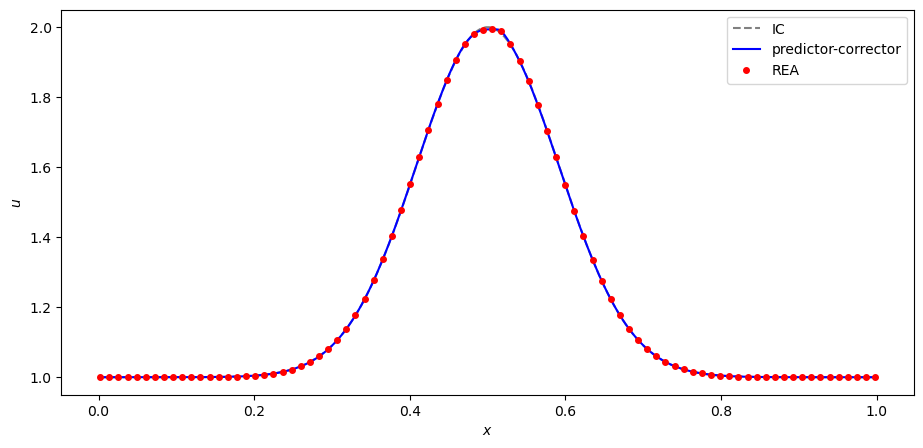

In [10]:
plt.figure(figsize = (11,5))

plt.plot(x, u0, color = "grey", linestyle = "--", label = "IC")
plt.plot(x, u_pc, color = "blue", label = "predictor-corrector")
plt.plot(x, u_rea, color = "red", linestyle = "none", marker = "o", markersize = 4, markevery = 3, label = "REA")

plt.xlabel(r"$x$")
plt.ylabel(r"$u$")

plt.legend()
plt.show()

## Part III. The method of lines

We have considered the flux as centred in time so far, by predicting the interface state to the half step. Instead, once the space derivative is discretised we are left with an ODE in time:

$$\frac{\partial u_i}{\partial t} = -\,\frac{c\,u_{i+1/2} - c\,u_{i-1/2}}{\Delta x}$$

There is no time level on the RHS. The interface states come from the reconstructed line alone, read off at the interface:

$$u_{i+1/2,L} = u_i + \tfrac{1}{2}\Delta u_i,
\qquad
u_{i+1/2,R} = u_{i+1} - \tfrac{1}{2}\Delta u_{i+1}$$

with no $(1-C)$ factor, because we are no longer advancing half a step. The Riemann problem resolves the two of them into one,

$$u_{i+1/2} = \mathcal{R}\left( u_{i+1/2,L},\, u_{i+1/2,R}\right)$$

and then we integrate the ODE in time.

### Which Runge-Kutta (RK)?

The time integrator has to be at least second order, or its error would spoil the second-order reconstruction.

We use **RK2**:

$$u^{\star} = u^{n} + \Delta t\,R(u^{n})$$

$$u^{n+1} = \tfrac{1}{2}u^{n} + \tfrac{1}{2}\left[ u^{\star} + \Delta t\,R(u^{\star})\right]$$

Each stage is a forward Euler step and the final state is an average of two of them.

The predictor-corrector carries the factor $(1-C)$ in its interface states, which cancels part of the spatial error and makes it most accurate near $C = 1$. The method of lines has no such term: its right-hand side never sees $\Delta t$.

### 1. The right-hand side of the ODE:

In [11]:
# The right-hand side R(u) of the ODE: minus the flux difference over dx.

def rhs(u, nx, ng, ilo, ihi, dx, c, method):

    # Fill up the BCs
    for n in range(ng):
        u[ilo - 1 - n] = u[ihi - n]
        u[ihi + 1 + n] = u[ilo + n]

    # Empty vector for the slope
    slope = np.zeros((nx + 2*ng), dtype = np.float64)

    if method == "godunov":
        slope[:] = 0.
    elif method == "unlimited":
        for i in range(ilo - 1, ihi + 2):
            slope[i] = 0.5*(u[i + 1] - u[i - 1])/dx
    elif method == "minmod":
        for i in range(ilo - 1, ihi + 2):
            slope[i] = minmod((u[i] - u[i-1])/dx, (u[i+1] - u[i])/dx)
    elif method == "mc":
        for i in range(ilo - 1, ihi + 2):
            slope[i] = minmod(minmod(2*(u[i] - u[i-1])/dx, 2*(u[i+1] - u[i])/dx), 0.5*(u[i+1] - u[i-1])/dx)

    # Empty vectors for the L and R states
    ul = np.zeros((nx + 2*ng), dtype = np.float64)
    ur = np.zeros((nx + 2*ng), dtype = np.float64)

    # Read off at the interface (no time predition)
    for i in range(ilo, ihi + 2):

        # L state
        ul[i] = u[i - 1] + 0.5*dx*slope[i-1]

        # R state
        ur[i] = u[i] - 0.5*dx*slope[i]

    # Riemann problem
    if c > 0.:
        flux = c*ul
    else:
        flux = c*ur

    # Empty vector for the right-hand side
    R = np.zeros((nx + 2*ng), dtype = np.float64)

    # Minus the flux difference over dx
    R[ilo:ihi+1] = -(flux[ilo+1:ihi+2] - flux[ilo:ihi+1])/dx

    return R

### 2. The RK2 time integration:

In [12]:
def advect_method_lines(nx, method, cfl = 0.5, num_periods = 1.):

    # Domain limits:
    xmin = 0.
    xmax = 1.

    # Number of ghost cells on each side
    ng = 2

    # Lowest and highest indices
    ilo = ng
    ihi = ng + nx - 1

    # Step size and cell centres
    dx = (xmax - xmin)/(nx)
    x = xmin + (np.arange(nx + 2*ng) - ng + 0.5)*dx

    # Empty vector for the solution in double precision:
    u = np.zeros((nx + 2*ng), dtype = np.float64)

    # Add initial conditions
    u[:] = 1. + np.exp(-60.*(x - 0.5)**2)

    # Make a copy of the initial condition:
    u0 = u.copy()

    # Define perturbation velocity
    c = 1.

    # Maximum simulation time
    tmax = num_periods*(xmax - xmin)/c

    # Initialise
    t = 0.

    # We start while:
    while t < tmax:

        # Get time step
        dt = cfl*dx/c

        if t + dt > tmax:
            dt = tmax - t

        # Slope 1: a full forward Euler step
        k1 = rhs(u, nx, ng, ilo, ihi, dx, c, method)
        ustar = u + dt*k1

        # Slope 2: a second Euler step, from the first one
        k2 = rhs(ustar, nx, ng, ilo, ihi, dx, c, method)

        # The new state is the average of the 2 slopes
        u = 0.5*u + 0.5*(ustar + dt*k2)

        # Advance in time
        t += dt

    return x[ilo:ihi+1], u[ilo:ihi+1], u0[ilo:ihi+1]

### 3. Does it advect correctly?

One period, 128 cells, $C = 0.8$, with the MC limiter. The predictor-corrector of notebook 14 is run on the same grid at the same Courant number.

In [13]:
# Predictor-corrector (notebook 14)
x, u_pc, u0 = advect(nx, "mc", cfl = 0.8, num_periods = 1.)

# Method of lines with SSP-RK2
x, u_mol, u0 = advect_method_lines(nx, "mc", cfl = 0.8, num_periods = 1.)

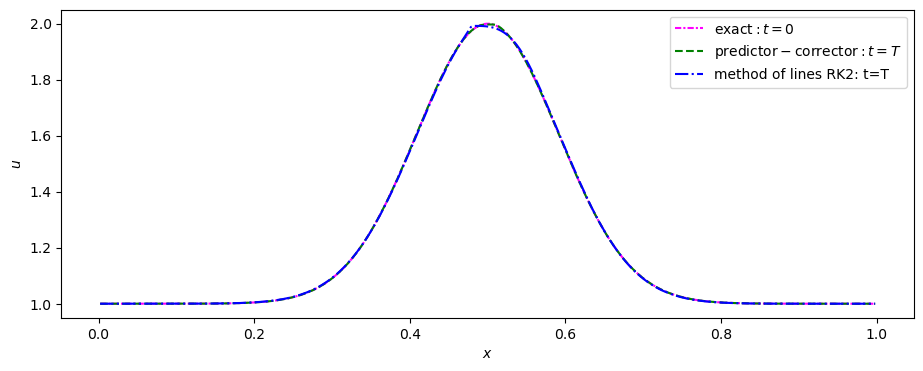

In [14]:
# Plotting both solutions against the initial condition

plt.figure(figsize=(11,4))

plt.plot(x, u0, color = "magenta", linestyle = (0, (3, 1, 1, 1)), label = r"${\rm exact}: t=0$")
plt.plot(x, u_pc, color = "green", linestyle = "--", label = r"${\rm predictor-corrector}: t=T$")
plt.plot(x, u_mol, color = "blue", linestyle = "-.", label = "method of lines RK2: t=T")

plt.xlabel(r"$x$")
plt.ylabel(r"$u$")
plt.legend()
plt.show()

### 4. Influence of the CFL number:

Now the same profile after 5 periods, with the method of lines run at $C = 0.8$ and at $C = 0.5$.

At $C = 0.8$ the peak lags by about three cells and the tail of the Gaussian is flattened out altogether.

The solution stays bounded (no instability) and the total variation never grows. It is simply that the time error is no longer small compared with the spatial error.

In [15]:
x, u_08, u0 = advect_method_lines(nx, "mc", cfl = 0.8, num_periods = 5.)
x, u_05, u0 = advect_method_lines(nx, "mc", cfl = 0.5, num_periods = 5.)

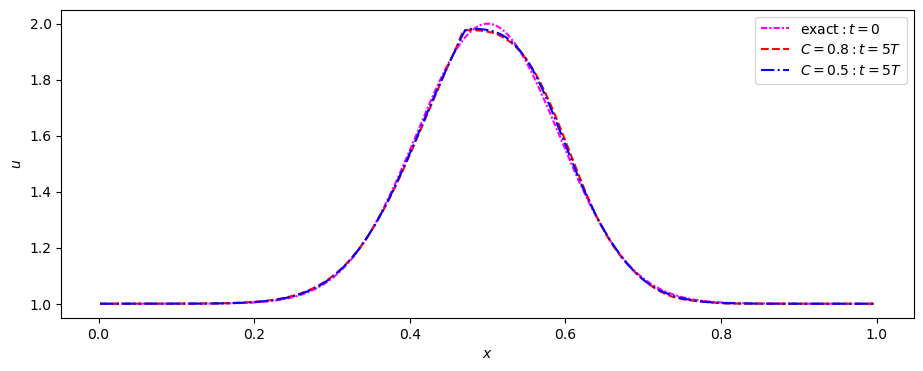

In [16]:
plt.figure(figsize=(11,4))

plt.plot(x, u0, color = "magenta", linestyle = (0, (3, 1, 1, 1)), label = r"${\rm exact}: t=0$")
plt.plot(x, u_08, color = "red", linestyle = "--", label = r"$C=0.8: t=5T$")
plt.plot(x, u_05, color = "blue", linestyle = "-.", label = r"$C=0.5: t=5T$")

plt.xlabel(r"$x$")
plt.ylabel(r"$u$")
plt.legend()
plt.show()


### 5. Order of accuracy:

In [17]:
# Convergence of the method of lines, at C = 0.8, 5 periods

errors_method_lines = []

for nx in nxs:
    x, u, u0 = advect_method_lines(int(nx), "unlimited", cfl = 0.8, num_periods = 5.)
    errors_method_lines.append(error(u, u0))

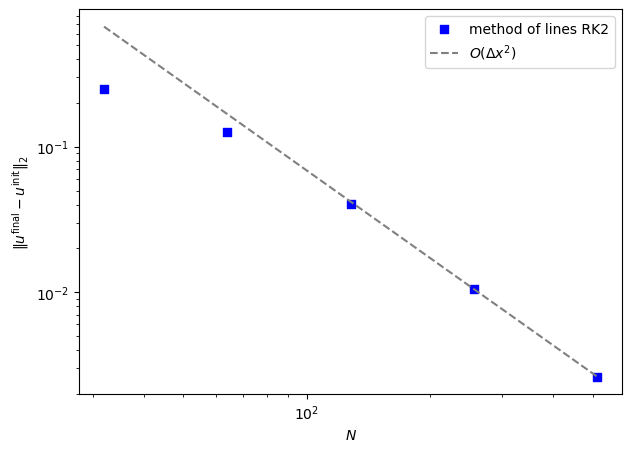

In [18]:
# Plotting the convergence of the method of lines

plt.figure(figsize=(7,5))

plt.scatter(nxs, errors_method_lines, marker = "s", color = "blue", label = r"method of lines RK2")

plt.plot(nxs, errors_method_lines[-1]*(nxs[-1]/nxs)**2, color = "grey", linestyle = "--", label = r"$O(\Delta x^2)$")

plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"$N$")
plt.ylabel(r"$\| u^{\rm final} - u^{\rm init}\|_2$")
plt.legend()
plt.show()

### Observations

- The method of lines advects correctly and converges at second order, as the table and the log-log plot show. The two routes are solving the same equation
  with the same reconstruction.

- They are not equally accurate at the same CFL number. The predictor-corrector wins at large $C$, because the time expansion it performs cancels part of the spatial error. The advantage disappears as $C$ falls.

- The method of lines prefers a smaller CFL number than the predictor-corrector method. The profile lags and the tail of the Gaussian is wiped out.

- The spatial reconstruction and the time integrator are now two independent choices. A piecewise-parabolic or WENO reconstruction can be dropped into the RHS without touching the time loop, and the Runge-Kutta order raised to match.